# Credit Card Fraud Detection
**Oasis Infobyte Internship · Data Analytics · Level 2 — Task 3**<br>
**Author:** Ojewumi Asaph Felix

**Objective:** build a machine learning pipeline that detects fraudulent credit card transactions in a **heavily imbalanced** dataset, and choose the right metrics to evaluate it.

**Dataset:** *Credit Card Fraud Detection* (ULB Machine Learning Group / Worldline, on Kaggle; copy from OpenML, dataset 1597) — **284,807 transactions made by European cardholders over 2 days in September 2013, of which 492 are frauds**. For confidentiality, the original features were transformed with PCA into `V1`…`V28`; only `Time` and `Amount` are in their original form.

> **Key results**
> - Only **0.17 %** of the transactions are frauds: a model that never detects any fraud would still be **99.8 % "accurate"**.
> - **SMOTE** oversampling (applied to the training set only) and evaluation with **precision, recall, F1 and the areas under the ROC and precision-recall curves**.
> - **Random Forest + SMOTE** is the best model: it catches **79 % of the frauds** and **93 % of its alerts are real frauds** (F1 = 0.85).
> - It scores ≈ 300,000 transactions per second on a laptop: **1 million transactions per hour is not a problem**.

**Contents**
1. Data loading and inspection
2. Class imbalance
3. Exploratory analysis: amounts and time of day
4. Why accuracy is misleading
5. Stratified train / test split
6. Handling the imbalance
7. Training two models
8. Evaluation: precision, recall, F1, ROC and PR curves
9. Recall vs. precision: which metric matters?
10. Feature importance
11. Scalability: 1 million transactions per hour
12. Conclusion

In [1]:
import time
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve, confusion_matrix, accuracy_score)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.3f}".format)

BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#b9b8b3", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#cfcecb", "axes.labelcolor": MUTED, "axes.titleweight": "bold",
    "axes.titlesize": 12.5, "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlepad": 12,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ecebe8", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

## 1. Data Loading and Inspection

In [2]:
raw = pd.read_csv("data/creditcard.csv.gz")
print("Shape:", raw.shape)
raw.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.000,-1.360,-0.073,2.536,1.378,-0.338,0.462,0.240,0.099,0.364,...,-0.018,0.278,-0.110,0.067,0.129,-0.189,0.134,-0.021,149.620,0
1,0.000,1.192,0.266,0.166,0.448,0.060,-0.082,-0.079,0.085,-0.255,...,-0.226,-0.639,0.101,-0.340,0.167,0.126,-0.009,0.015,2.690,0
2,1.000,-1.358,-1.340,1.773,0.380,-0.503,1.800,0.791,0.248,-1.515,...,0.248,0.772,0.909,-0.689,-0.328,-0.139,-0.055,-0.060,378.660,0
3,1.000,-0.966,-0.185,1.793,-0.863,-0.010,1.247,0.238,0.377,-1.387,...,-0.108,0.005,-0.190,-1.176,0.647,-0.222,0.063,0.061,123.500,0
4,2.000,-1.158,0.878,1.549,0.403,-0.407,0.096,0.593,-0.271,0.818,...,-0.009,0.798,-0.137,0.141,-0.206,0.502,0.219,0.215,69.990,0


In [3]:
print("Missing values :", raw.isna().sum().sum())
print("Duplicated rows:", raw.duplicated().sum(), "including", raw[raw.duplicated()]["Class"].sum(), "frauds")
df = raw.drop_duplicates().reset_index(drop=True)
print("Transactions after removing duplicates:", len(df))
print(f"Time covered: {df['Time'].max() / 3600:.0f} hours (2 days)")
df[["Time", "Amount"]].describe().T

Missing values : 0


Duplicated rows: 1081 including 19 frauds


Transactions after removing duplicates: 283726
Time covered: 48 hours (2 days)


,count,mean,std,min,25%,50%,75%,max
Time,"283,726.000","94,811.078","47,481.048",0.000,"54,204.750","84,692.500","139,298.000","172,792.000"
Amount,"283,726.000",88.473,250.399,0.000,5.600,22.000,77.510,"25,691.160"


**Observations:**
- 31 columns: `Time` (seconds since the first transaction), `V1`–`V28` (anonymised PCA components), `Amount` (in euros) and `Class` (1 = fraud). **No missing values.**
- **1,081 rows are exact duplicates** (all 30 features identical). They are removed so that the same transaction cannot appear in both the training and the test set.
- The `V` features are already centred and scaled by the PCA; `Amount` is not (from 0 to 25,691 €), so it must be **standardised** for Logistic Regression.

## 2. Class Imbalance: What Percentage of Transactions Are Fraudulent?

Class
legitimate    283253
fraud            473

Fraud rate: 0.167%  →  1 fraud for every 599 legitimate transactions


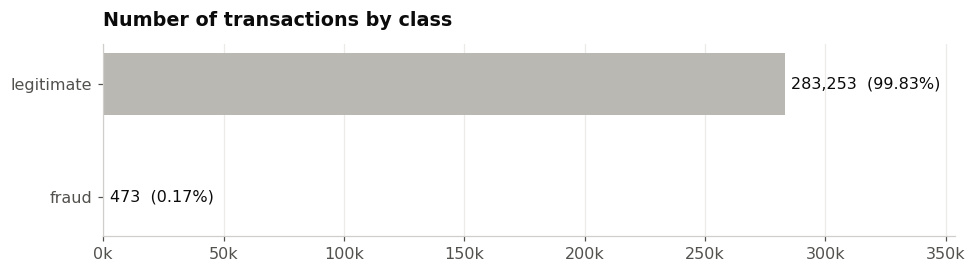

In [4]:
counts = df["Class"].value_counts().rename({0: "legitimate", 1: "fraud"})
print(counts.to_string())
print(f"\nFraud rate: {counts['fraud'] / counts.sum():.3%}  →  1 fraud for every {counts['legitimate'] / counts['fraud']:,.0f} legitimate transactions")

fig, ax = plt.subplots(figsize=(9, 2.6))
ax.barh(["fraud", "legitimate"], [counts["fraud"], counts["legitimate"]], color=[ORANGE, GREY], height=0.55)
for y, v in enumerate([counts["fraud"], counts["legitimate"]]):
    ax.text(v + 2500, y, f"{v:,}  ({v / counts.sum():.2%})", va="center", color=INK)
ax.set_xlim(0, counts.max() * 1.25)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f}k"))
ax.set_title("Number of transactions by class")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("images/class_imbalance.png")
plt.show()

**Only 473 frauds out of 283,726 transactions (0.17 %)** — about 1 fraud for every 600 legitimate transactions. The fraud bar is almost invisible: this extreme imbalance is the core challenge of the task.

## 3. Exploratory Analysis
### 3.1 Transaction amounts: fraud vs. non-fraud

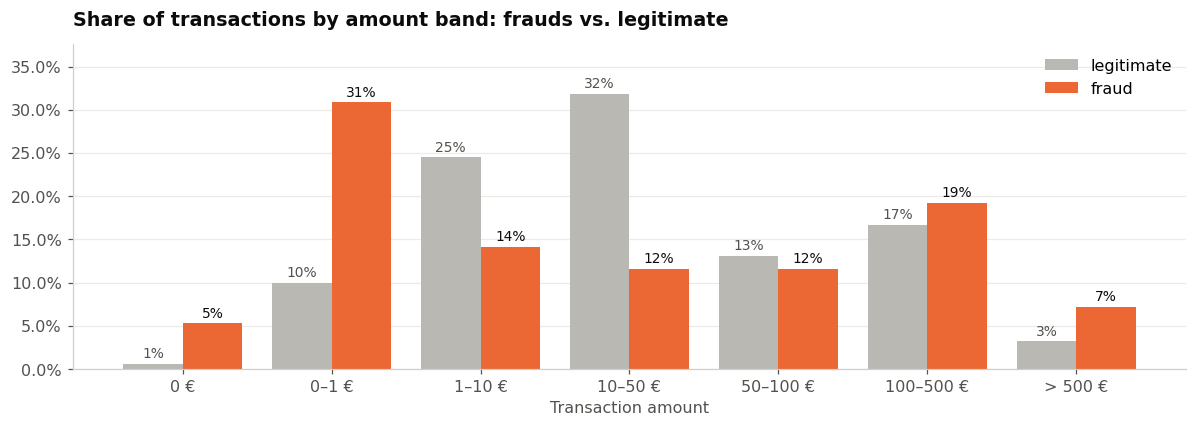

,mean,25%,50%,75%,max
Class,,,,,
fraud,123.872,1.000,9.820,105.890,"2,125.870"
legitimate,88.414,5.670,22.000,77.460,"25,691.160"


In [5]:
bands = pd.cut(df["Amount"], bins=[-0.01, 0, 1, 10, 50, 100, 500, np.inf],
               labels=["0 €", "0–1 €", "1–10 €", "10–50 €", "50–100 €", "100–500 €", "> 500 €"])
share = pd.crosstab(bands, df["Class"].map({0: "legitimate", 1: "fraud"}), normalize="columns")

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(share))
b1 = ax.bar(x - 0.2, share["legitimate"], width=0.4, color=GREY, label="legitimate")
b2 = ax.bar(x + 0.2, share["fraud"], width=0.4, color=ORANGE, label="fraud")
ax.bar_label(b2, labels=[f"{v:.0%}" for v in share["fraud"]], padding=2, color=INK, fontsize=9)
ax.bar_label(b1, labels=[f"{v:.0%}" for v in share["legitimate"]], padding=2, color=MUTED, fontsize=9)
ax.set_xticks(x, share.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, share.values.max() * 1.18)
ax.set_xlabel("Transaction amount")
ax.set_title("Share of transactions by amount band: frauds vs. legitimate")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("images/amounts.png")
plt.show()

df.groupby(df["Class"].map({0: "legitimate", 1: "fraud"}))["Amount"].describe()[["mean", "25%", "50%", "75%", "max"]]

**Observations:**
- Frauds are **polarised**: they are over-represented among **tiny amounts** and among **amounts above 100 €** (26 % of frauds vs. 20 % of legitimate payments), and rare in the everyday 1–50 € range. The median fraud is only **≈ 10 €** (vs. ≈ 22 €), and the largest fraud is 2,126 €.
- **36 % of frauds are 1 € or less** (22 % are almost exactly 1 €), against only 11 % of legitimate payments: fraudsters often **test a stolen card** with a tiny payment before using it.
- The mean fraud (124 €) is higher than the mean legitimate payment (88 €) because of these larger frauds. Since frauds exist at every amount, **amount alone cannot detect fraud.**

### 3.2 Time-of-day analysis
`Time` counts the seconds since the first transaction. We convert it to an **hour of the day** (`hour = (Time / 3600) mod 24`). The real clock time is not given, but the clear drop in activity between hours 1 and 7 strongly suggests that hour 0 corresponds to **midnight**.

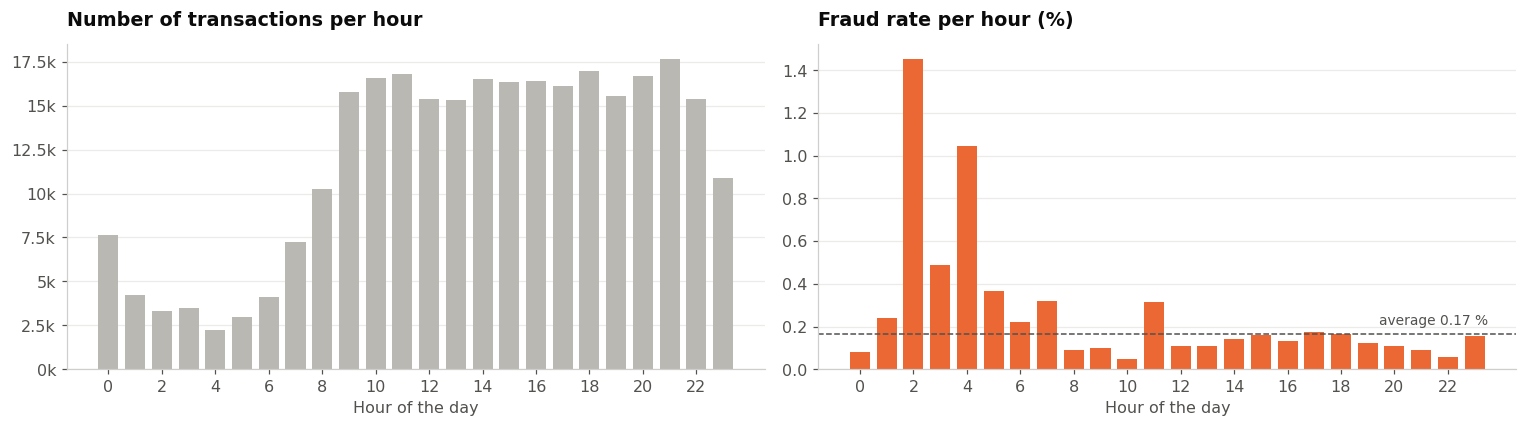

,transactions,frauds,fraud rate (%)
Hour,,,
2,3308,48,1.451
4,2204,23,1.044
3,3487,17,0.488
5,2988,11,0.368
7,7233,23,0.318


In [6]:
df["Hour"] = (df["Time"] // 3600 % 24).astype(int)
by_hour = df.groupby("Hour").agg(transactions=("Class", "size"), frauds=("Class", "sum"))
by_hour["fraud rate (%)"] = by_hour["frauds"] / by_hour["transactions"] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(by_hour.index, by_hour["transactions"], color=GREY, width=0.75)
axes[0].set_title("Number of transactions per hour")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:g}k"))
b = axes[1].bar(by_hour.index, by_hour["fraud rate (%)"], color=ORANGE, width=0.75)
axes[1].set_title("Fraud rate per hour (%)")
axes[1].axhline(df["Class"].mean() * 100, color=MUTED, ls="--", lw=1)
axes[1].text(23.5, df["Class"].mean() * 100 + 0.04, "average 0.17 %", ha="right", color=MUTED, fontsize=9)
for ax in axes:
    ax.set_xlabel("Hour of the day")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("images/time_of_day.png")
plt.show()
by_hour.sort_values("fraud rate (%)", ascending=False).head(5)

**Observations:**
- Activity is **low between hours 1 and 7** (night) and high during the day.
- The **fraud rate peaks at night**: **1.45 % at hour 2 and 1.04 % at hour 4**, i.e. 6 to 9 times the average. Fraudsters act when cardholders are asleep and less likely to notice.
- In absolute numbers frauds are spread over the day, but **a night-time transaction deserves more attention**.

## 4. Why Accuracy Is Misleading
**Accuracy** = share of correct predictions. With 99.83 % legitimate transactions, a "model" that **always answers "not fraud"** is almost always right — and **never catches a single fraud**:

In [7]:
always_legit = np.zeros(len(df), dtype=int)
print(f"Accuracy of 'never fraud' : {accuracy_score(df['Class'], always_legit):.2%}")
print(f"Frauds detected           : {recall_score(df['Class'], always_legit):.0%}")

Accuracy of 'never fraud' : 99.83%
Frauds detected           : 0%


So we use metrics that focus on the **fraud class**:
- **Precision** = among the transactions flagged as fraud, how many really are frauds? (*how many false alarms?*)
- **Recall** = among all real frauds, how many did we catch? (*how many frauds slip through?*)
- **F1-score** = the harmonic mean of precision and recall (one number to balance both).
- **ROC AUC** = ability to rank frauds above legitimate transactions, over all thresholds.
- **PR AUC (average precision)** = the same idea on the precision-recall curve; **more informative than ROC AUC when the positive class is very rare**, because it is not inflated by the huge number of true negatives.

## 5. Stratified Train / Test Split (80 / 20)
With so few frauds, a random split could leave very few of them in the test set. **Stratification** keeps the 0.17 % fraud rate in both sets.

In [8]:
FEATURES = [f"V{i}" for i in range(1, 29)] + ["Amount"]
X, y = df[FEATURES], df["Class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train: {len(X_train):,} transactions, {y_train.sum()} frauds ({y_train.mean():.3%})")
print(f"Test : {len(X_test):,} transactions, {y_test.sum()} frauds ({y_test.mean():.3%})")

Train: 226,980 transactions, 378 frauds (0.167%)
Test : 56,746 transactions, 95 frauds (0.167%)


`Time` is not used as a model input: it counts seconds over only two days, so it would not generalise to new data. Its useful information (the hour) was studied in section 3.

## 6. Handling the Imbalance
We compare three strategies with a fast model (Logistic Regression):
1. **Nothing** (the model sees 600 legitimate transactions for each fraud);
2. **`class_weight="balanced"`**: errors on frauds cost 600× more during training;
3. **SMOTE** (*Synthetic Minority Over-sampling Technique*): creates **synthetic frauds** by interpolating between real neighbouring frauds.

⚠️ SMOTE is placed **inside the pipeline**, so it is applied **only to the training data** — the test set keeps only real transactions.

In [9]:
def scores(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"Precision": precision_score(y_true, pred, zero_division=0), "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred), "ROC AUC": roc_auc_score(y_true, proba),
            "PR AUC": average_precision_score(y_true, proba)}

strategies = {
    "No handling": Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=2000))]),
    "class_weight='balanced'": Pipeline([("scale", StandardScaler()),
                                         ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "SMOTE": ImbPipeline([("scale", StandardScaler()), ("smote", SMOTE(random_state=42)),
                          ("model", LogisticRegression(max_iter=2000))]),
}
imbalance = pd.DataFrame({name: scores(y_test, m.fit(X_train, y_train).predict_proba(X_test)[:, 1])
                          for name, m in strategies.items()}).T
imbalance

,Precision,Recall,F1,ROC AUC,PR AUC
No handling,0.846,0.579,0.688,0.956,0.692
class_weight='balanced',0.056,0.874,0.105,0.965,0.675
SMOTE,0.053,0.874,0.099,0.960,0.676


**Observations:**
- **Without handling**, Logistic Regression is cautious: few false alarms (precision 0.85) but it **misses 42 % of the frauds** (recall 0.58).
- **class_weight and SMOTE** both push recall up to **0.87**, but at the default threshold of 0.5 the model now raises **far too many alarms** (precision ≈ 0.05: only 1 alert in 20 is a real fraud).
- The ROC AUC hardly changes: the three versions **rank** transactions almost equally well; the strategies mainly move the **decision threshold**. A linear model cannot separate frauds cleanly — we need a more flexible model.

## 7. Training Two Models
1. **Logistic Regression + SMOTE** — simple, fast and interpretable reference model.
2. **Random Forest + SMOTE** — an ensemble of 100 decision trees that captures non-linear patterns. Here SMOTE raises the frauds to **10 % of the legitimate transactions** (`sampling_strategy=0.1`): enough to rebalance the learning, while keeping training fast and limiting the number of synthetic points.

In [10]:
models = {
    "Logistic Regression + SMOTE": strategies["SMOTE"],
    "Random Forest + SMOTE": ImbPipeline([("smote", SMOTE(sampling_strategy=0.1, random_state=42)),
                                          ("model", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42))]),
}
probas = {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    probas[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name:<28} trained in {time.time() - start:5.1f} s")

Logistic Regression + SMOTE  trained in   2.4 s


Random Forest + SMOTE        trained in  69.1 s


## 8. Evaluation

In [11]:
results = pd.DataFrame({name: scores(y_test, p) for name, p in probas.items()}).T
results

,Precision,Recall,F1,ROC AUC,PR AUC
Logistic Regression + SMOTE,0.053,0.874,0.099,0.960,0.676
Random Forest + SMOTE,0.926,0.789,0.852,0.959,0.828


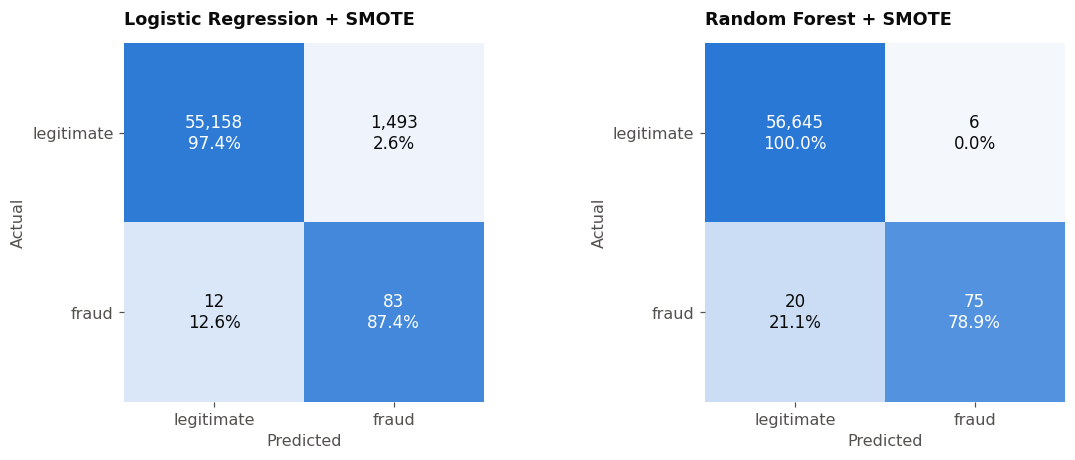

In [12]:
cmap = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", BLUE])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (name, p) in zip(axes, probas.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap=cmap, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            share = cm[i, j] / cm[i].sum()
            ax.text(j, i, f"{cm[i, j]:,}\n{share:.1%}", ha="center", va="center",
                    color="white" if share > 0.55 else INK, fontsize=11)
    ax.set_xticks([0, 1], ["legitimate", "fraud"]); ax.set_yticks([0, 1], ["legitimate", "fraud"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(name, fontsize=11.5)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
plt.tight_layout()
plt.savefig("images/confusion_matrices.png")
plt.show()

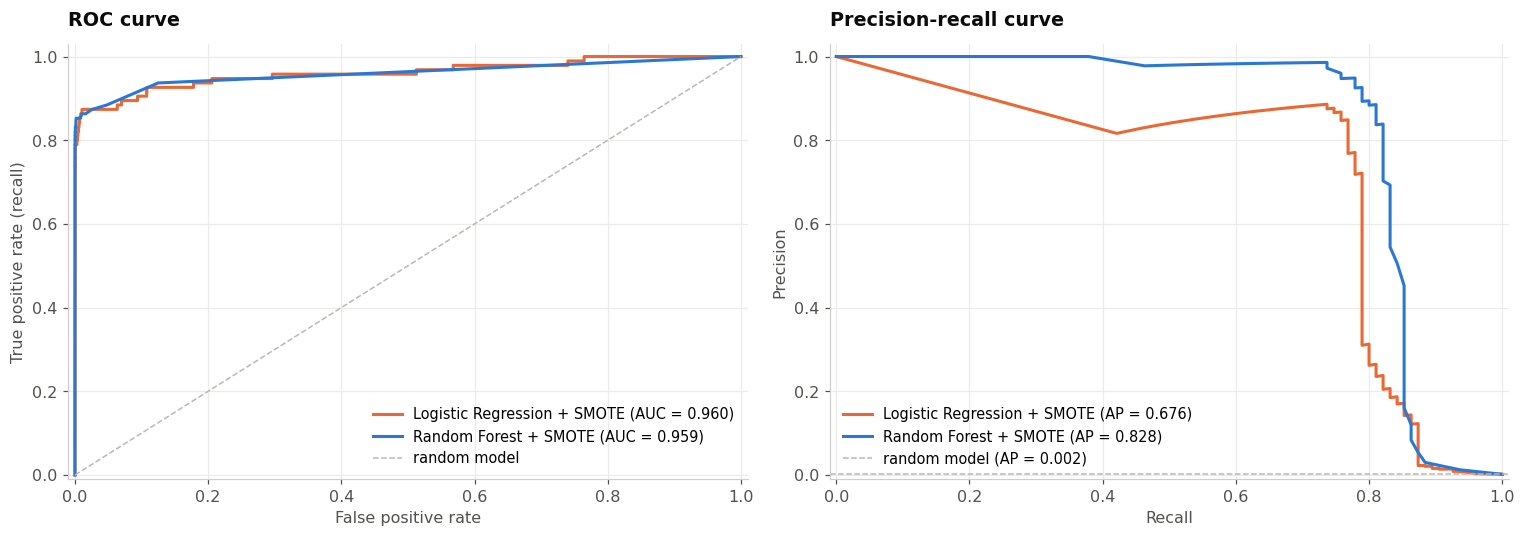

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {"Logistic Regression + SMOTE": ORANGE, "Random Forest + SMOTE": BLUE}
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=colors[name], lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=colors[name], lw=2, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="random model")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve")
axes[1].axhline(y_test.mean(), color=GREY, ls="--", lw=1, label=f"random model (AP = {y_test.mean():.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve")
for ax in axes:
    ax.legend(frameon=False, loc="lower right" if ax is axes[0] else "lower left", fontsize=9.5)
    ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.03)
plt.tight_layout()
plt.savefig("images/roc_pr_curves.png")
plt.show()

**Observations:**
- **Random Forest + SMOTE is clearly the best model**: it catches **≈ 79 % of the frauds** while **≈ 93 % of its alerts are real frauds** (F1 ≈ 0.85). Only **6 legitimate transactions** out of 56,651 are wrongly blocked.
- Logistic Regression + SMOTE catches more frauds at the default threshold (≈ 87 %), but with **almost 1,500 false alarms (1,493)** — unworkable for a bank.
- Both ROC AUCs are high (> 0.95), which shows that **ROC AUC is too optimistic here**. The **precision-recall curve** separates the models much better: the Random Forest keeps a high precision until a recall of about 0.8.

## 9. Recall vs. Precision: Which Metric Matters Most?
- A **missed fraud** (false negative) costs the bank the **stolen amount**, plus chargeback fees and customer trust.
- A **false alarm** (false positive) costs a **blocked card, an SMS or a call** to the customer, and some frustration.

👉 For fraud detection, **recall is usually the priority**: missing a fraud is more expensive than checking a legitimate payment. But precision cannot be ignored: if 95 % of alerts are false, analysts cannot handle the volume and customers stop trusting the alerts.

The **decision threshold** lets the bank choose its trade-off. By default a transaction is flagged when the fraud probability ≥ 0.5; lowering it catches more frauds at the cost of more alerts:

In [14]:
rf_proba = probas["Random Forest + SMOTE"]
rows = []
for t in [0.1, 0.2, 0.3, 0.5, 0.7]:
    pred = (rf_proba >= t).astype(int)
    rows.append({"threshold": t, "frauds caught": int(((pred == 1) & (y_test == 1)).sum()),
                 "frauds missed": int(((pred == 0) & (y_test == 1)).sum()),
                 "false alarms": int(((pred == 1) & (y_test == 0)).sum()),
                 "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})
pd.DataFrame(rows).set_index("threshold")

,frauds caught,frauds missed,false alarms,precision,recall,F1
threshold,,,,,,
0.100,81,14,146,0.357,0.853,0.503
0.200,78,17,33,0.703,0.821,0.757
0.300,77,18,14,0.846,0.811,0.828
0.500,75,20,6,0.926,0.789,0.852
0.700,72,23,4,0.947,0.758,0.842


**Reading the table:** moving the threshold from 0.5 to **0.3** catches **2 more frauds for 8 more false alarms**, and 0.2 catches 3 more frauds for 27 more alarms. If a missed fraud costs hundreds of euros and a check costs a phone call, a lower threshold is worth it; going down to 0.1 multiplies the alarms by 24 for little gain. The final threshold should be chosen **with the business**, from the real cost of each type of error.

## 10. Feature Importance

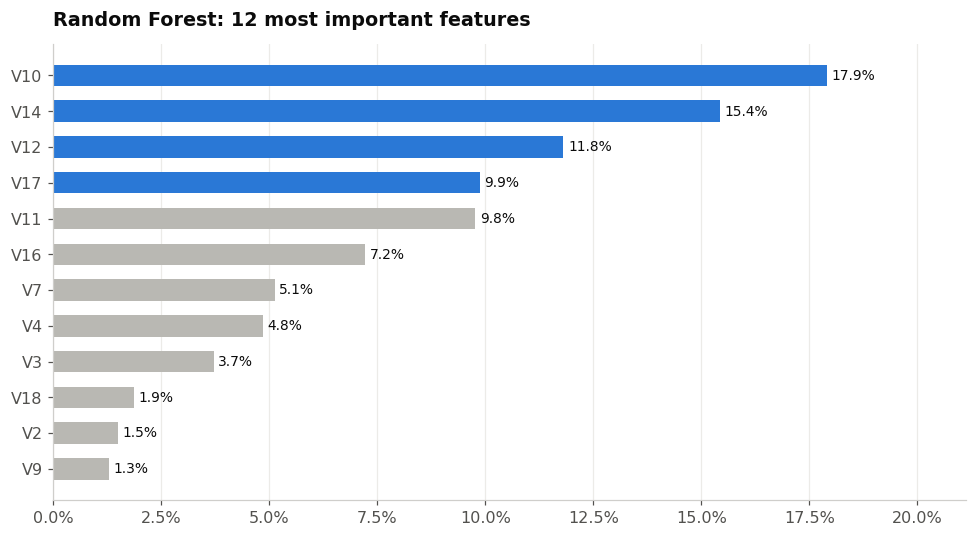

In [15]:
rf = models["Random Forest + SMOTE"].named_steps["model"]
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values().tail(12)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(importance.index, importance.values, color=[BLUE if v >= importance.nlargest(4).min() else GREY for v in importance.values], height=0.6)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in importance.values], padding=3, color=INK, fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(0, importance.max() * 1.18)
ax.set_title("Random Forest: 12 most important features")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("images/feature_importance.png")
plt.show()

In [16]:
lr = models["Logistic Regression + SMOTE"].named_steps["model"]
coef = pd.Series(lr.coef_[0], index=FEATURES)
pd.DataFrame({"Logistic Regression coefficient": coef.loc[coef.abs().sort_values(ascending=False).index[:8]]})

,Logistic Regression coefficient
Amount,1.937
V14,-1.585
V1,1.501
V10,-1.389
V4,1.309
V12,-1.273
V5,1.084
V17,-0.913


**Observations:**
- A handful of PCA components carry most of the signal: **V10, V14, V12, V17 and V11** make up almost two thirds of the Random Forest's importance. **V14, V10, V12 and V17** also have large coefficients in the Logistic Regression: the two models largely agree.
- They disagree on **Amount**: the Random Forest barely uses it (it is not even in its top 12), while it gets the largest coefficient in the Logistic Regression. On its own the amount says little (section 3); it only becomes informative **combined with the V components**, and a linear model needs it to compensate for what it cannot capture with straight boundaries.
- Because the `V` features are anonymised PCA components, we cannot say *what* they represent (merchant, location, device…). In a real bank, the original features would make the model's decisions explainable to analysts.

## 11. Scalability: How Would This Model Handle 1 Million Transactions per Hour?
1 million transactions per hour = **≈ 280 transactions per second**. Let us measure how fast the trained Random Forest scores transactions on this laptop:

In [17]:
batch = pd.concat([X_test] * 4, ignore_index=True)           # ≈ 227,000 transactions
start = time.time()
models["Random Forest + SMOTE"].predict_proba(batch)
elapsed = time.time() - start
print(f"Scored {len(batch):,} transactions in {elapsed:.2f} s  →  {len(batch) / elapsed:,.0f} transactions per second")
print(f"1,000,000 transactions would take ≈ {1e6 / (len(batch) / elapsed):.1f} s of computing time per hour")

Scored 226,984 transactions in 0.81 s  →  281,481 transactions per second
1,000,000 transactions would take ≈ 3.6 s of computing time per hour


**Scoring is not the bottleneck**: the model handles in a few seconds what arrives in one hour. (SMOTE is only used during training, so it adds nothing at prediction time.) In production the real challenges are elsewhere:
1. **Real-time architecture** — the model runs behind an API or in a **streaming** pipeline (e.g. Kafka + a scoring service) so that each payment gets a score in a few milliseconds, **before** it is approved. Several replicas behind a load balancer absorb peaks.
2. **Latency budget** — a payment must be authorised in well under a second; a 100-tree forest predicts one transaction in about a millisecond, so it fits, but larger models may need to be reduced (fewer/shallower trees, or gradient boosting such as LightGBM).
3. **Retraining and drift** — fraudsters change tactics: the model must be **retrained regularly** (e.g. weekly) on recent labelled data, and its precision/recall **monitored** continuously.
4. **Delayed labels** — a fraud is often confirmed days later (chargeback), so the latest data is incompletely labelled.
5. **Human in the loop** — the threshold should match the **capacity of the analyst team** that reviews alerts.

## 12. Conclusion
- The dataset is **extremely imbalanced (0.17 % frauds)**: accuracy is useless, so the models were judged on **precision, recall, F1, ROC AUC and above all PR AUC**.
- **SMOTE**, applied to the training set only, helps the models learn the fraud class. With a linear model it mostly shifts the threshold; with a **Random Forest** it gives the best result.
- **Random Forest + SMOTE** catches **≈ 79 % of frauds with ≈ 93 % precision** (F1 ≈ 0.85, PR AUC ≈ 0.83), with only a handful of false alarms — **the model to deploy**, with a threshold set together with the business.
- Frauds are often **small test payments** and are **more frequent at night**.
- The model is **fast enough for 1 million transactions per hour**; the real production work is real-time integration, monitoring and regular retraining.

**Limitations:** two days of data from 2013; anonymised features (no explanation of individual decisions); the test set contains only ≈ 95 frauds, so recall can move by a few points with a different split.